# 101_06 — Comportamientos como opciones de pronóstico · Tráfico I-94, rezago 1 (la 31 con el pipeline 30x)

Sobre los artefactos del `_04` (`draws_scores_psbp.npy`, `comportamientos_psbp.npz`, `banda_funcional_psbp.npz`) y los competidores del `_05` (FAR y RF, reajustados con las mismas funciones y semilla). Dos predicciones por origen a partir de los comportamientos: el **más probable** (un algoritmo de pronóstico) y el **mejor comportamiento** (una cota que usa lo observado). Cada una contra FAR y RF por separado, sobre la ventana móvil, por origen y contra `M`. Nada de lo que escribe pisa salidas del `_04` o del `_05` (prefijos 113–119).

## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import matplotlib.pyplot as plt
import pandas as pd
import json

import numpy as np

from model_psbp_fd.fit.convergencia_barrido import cargar_artefactos
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB, cargar_representaciones, serie_origenes,
)
from model_psbp_fd.fit.comparacion_barrido import (
    G_FAR, G_PSG, G_PSB, PISO,
    preparar_diseno, ajustar_far, ajustar_rf, cargar_psbp,
    tablas_modelos, verificar_cadena_modelos,
    construir_bandas, tabla_bloque_B, ventana_bloque_B,
    ganadores_por_ventana, resumen_min_max, promedio_vs_M,
    origenes_extremos, contraste_origenes, nombre_psbp, validar_comportamientos_barrido,
    G_PSS, G_PSH, bloqueB_contra_far,
)
from model_psbp_fd.fit.evaluacion_barrido import INTERVALOS as INTERVALOS_TODOS
from model_psbp_fd.fit.resumenes_predictiva import PREDICTORES as PREDICTORES_TODOS
from model_psbp_fd.graphics import (
    plot_ventana_movil, ESTILOS_MODELOS, ESTILOS_MODELOS_PREDICTORES, plot_validacion_observado,
    plot_ganador_modelo, plot_metricas_vs_M, plot_bandas_contraste,
)
from model_psbp_fd.fit.comportamientos import cargar_comportamientos, validar_observado
from model_psbp_fd.fit.intervalos_predictiva import ancho_tramos, cobertura_tramos
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

# Propios del _06: opciones por comportamiento y errores por origen.
from model_psbp_fd.fit.resumenes_predictiva import mediana_puntual, medoide_l1
from model_psbp_fd.fit.comportamientos import recortar, _a_curva
from model_psbp_fd.fit.metrics_puntual import normas_error_por_origen
from model_psbp_fd.pipelines.artifacts import cargar_draws_scores


### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 101_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "trafico_101", 1   # ventana 1: 2015-07-01 .. 2018-09-30, 70/30 (31_01 §1.1; artefactos copiados por 00_copiar_31.py)
M_FPCA_LIST = (10,)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None

# Propias de la comparación. Ventanas, nivel y objetivo se LEEN de eval_config.json
# (artefacto de 101_01): no se redeclaran aquí.
PESOS_TAU = None          # cuadratura trapezoidal por defecto
PREFIJO   = 70            # este notebook escribe 70-83 en cada M y 96-99, 105-107, 111 en el barrido
INTERVALOS  = INTERVALOS_TODOS    # equicolas, simultanea, hdr: una banda del PSBPM-FD por construcción
N_DETALLE   = 10        # orígenes consecutivos de prueba para el análisis predictivo (§9, §10)
T0_DETALLE  = None      # el _05 LEE la ventana del _04 (112_ventana_detalle.json); un entero sólo la verifica
PREDICTORES = PREDICTORES_TODOS   # una fila del PSBPM-FD por predictor puntual (101_04 §3)

# FAR (§3.1): FAR(1), p = N_LAGS = 1 fijo, como en la 31. Tope del barrido de kn
# (acota en K = 10, no en L) y criterio de far.cv.
KN_MAX      = 12
CRITERIO_KN = "L2"

# Random Forest (§3.2): hiperparámetros fijos entre escenarios y entre puntos del barrido.
SEED_ML   = 20260830
PARAMS_RF = dict(n_estimators=500, min_samples_leaf=5, max_features="sqrt",
                 random_state=SEED_ML, n_jobs=-1)

# Bloque B (§5): FAR con banda gaussiana de residuos de train y PSBPM-FD con su banda
# nativa (cuantiles de su predictiva).
IC_POR_TAU                = True    # sigma_eps(tau) punto a punto (False = ancho constante)
IC_CORRECCION_ESTIMACION  = True    # infla sigma por sqrt(1 + kn/n_train)
IC_PSBP_TAMBIEN_GAUSSIANA = False   # control opcional: no se corre (sólo FAR gaussiano y PSBPM-FD nativo)

# §9: por qué métrica se eligen los orígenes extremos, cuántos, qué dos bandas se
# contrastan (prefijos, en orden) y en qué M (None = todos).
METRICA_SEL_IC     = "rmse_f"     # una de METRICAS_A_COLS
N_EXTREMOS         = 5
BANDA_A_CONTRASTAR = ("FAR", "PSBPM-FD (predictiva")
M_DETALLE          = None

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]
assert METRICA_SEL_IC in METRICAS_A_COLS[:3], "METRICA_SEL_IC: mae_f, rmse_f o linf_medio."

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}   (archivos 96-99, 105-107)")

# ---- Propias del _06 ----------------------------------------------------------------
OPCIONES     = ("tipica", "mediana", "medoide")  # resumen de la condicional de cada comportamiento
OPCION_FIG   = "tipica"                          # la opción que va en las figuras (las tablas llevan las tres)
PREFIJO_06   = 113                               # por M: 113-115; barrido: 116-119
TRAMOS_P1    = (0.5, 0.6, 0.7, 0.8, 0.9, 1.0 + 1e-9)   # tramos de la masa del comportamiento más probable

# Ancho de referencia del documento: None = el de siempre (el del medio, 30; decisión 2026-10-12, para no
# reejecutar el _04). Un entero de VENTANAS_W sobrescribe DIS["W_REF"] sin tocar eval_config.json.
W_REF_DOC = None

EXPERIMENT_BASE : real_trafico_101_v01
barrido en M    : [10]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_101_v01_barrido_M   (archivos 96-99, 105-107)


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True, dominio=DOMINIO)
DIS  = cargar_representaciones(EST)
ORIG = serie_origenes(DIS)

T0, N_LAGS, NIVEL = DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W = DIS["VENTANAS_W"]
if W_REF_DOC is not None:
    assert int(W_REF_DOC) in VENTANAS_W, f"W_REF_DOC={W_REF_DOC} no está en {VENTANAS_W}"
    DIS["W_REF"] = int(W_REF_DOC)
W_REF = DIS["W_REF"]
print(f"ancho de referencia de este notebook: w = {W_REF}" + ("  (W_REF_DOC)" if W_REF_DOC is not None else ""))
grilla, X_obj_ev  = DIS["grilla"], ORIG["X_obj_ev"]
t_orig, es_train  = ORIG["t_orig"], ORIG["es_train"]

  M  comp  cadenas  covariables  seed_base
 10    10        1           10  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)
M=10  FPCA M=10 K=10  var. explicada=100.0000%  ·  curvas (1188, 24)

OK 1 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1188 T0=831 n_lags=1   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95
ancho de referencia de este notebook: w = 30


## 2. Competidores: FAR y RF como en el `_05`, y los predictores del PSBPM-FD

In [4]:
preparar_diseno(EST, DIS, ORIG)
# Rezagos efectivos del diseño (manifest["lags"]); N_LAGS = max(lags) es el desplazamiento y el orden del FAR completo.
LAGS = tuple(int(l) for l in EST[next(iter(EST))]["manifest"].get("lags", range(1, N_LAGS + 1)))
print(f"rezagos efectivos de las covariables: {LAGS}   ·   N_LAGS = {N_LAGS} (desplazamiento; FAR({N_LAGS}))")


origenes evaluados: 1187  (train 830 · test 357)
MISE del TRUNCAMIENTO FPCA (piso comun a todos los modelos de cada M):
  M=10   train 0.000000   test 0.000000
rezagos efectivos de las covariables: (1,)   ·   N_LAGS = 1 (desplazamiento; FAR(1))


In [5]:
FAR = ajustar_far(EST, DIS, ORIG, KN_MAX, CRITERIO_KN)

base: K = 10   ·   cond(W) = 8.44   ·   ||x||_L2 == ||theta_w||_2 (error relativo 5.08e-11)
far.cv: hold-out de las ultimas 166 curvas de train · kn_max = 10
  kn         L1         L2       Linf      L1max      L2max    Linfmax
   1     0.1702     0.2375     0.5463     0.3161     0.3557     0.7457
   2     0.1613     0.2237     0.5151     0.3021     0.3537     0.7830
   3     0.1516     0.2131     0.4921     0.3035     0.3522     0.7491
   4     0.1314     0.1813     0.4097     0.2575     0.3103     0.7134
   5     0.1210     0.1656     0.3703     0.2355     0.2919     0.6943
   6     0.1194     0.1638     0.3679     0.2294     0.2861     0.6914
   7     0.1165     0.1607     0.3617     0.2262     0.2859     0.6676
   8     0.1142     0.1561     0.3484     0.2125     0.2800     0.7845
   9     0.1133     0.1552     0.3469     0.2098     0.2765     0.8021
  10     0.1132     0.1550     0.3459     0.2102     0.2776     0.8104  <-
kn elegido por L2: 10   (L1 -> 10, Linf -> 10)   amplitud

In [6]:
ajustar_rf(EST, DIS, ORIG, PARAMS_RF, PESOS_TAU, ordenes=LAGS)

M=10: RF orden=1   ·   10 modelos univariantes (rezagos de todas las componentes)


In [7]:
M_OK = cargar_psbp(EST, DIS, ORIG, predictores=PREDICTORES, intervalos=INTERVALOS)

OK PSBPM-FD leido del _04 en M = [10]


## 3. Opciones por origen: la condicional de cada comportamiento

Curva típica (centroide), mediana puntual y medoide de las extracciones de cada grupo.

In [8]:
# Opciones por origen: para cada comportamiento c de cada origen, tres resúmenes de su condicional.
# Las etiquetas de las extracciones se recuperan por centroide más cercano (los grupos de k-medias
# son las celdas de Voronoi de sus centroides) sobre los draws recortados, como en el _04 §12.

def _etiquetas(Z, cen):
    return np.argmin(((Z[:, None, :] - cen[None]) ** 2).sum(-1), axis=1)


def opciones_origen(C, SC, a_curva, tau, pesos_tau):
    S, n, _ = SC.shape
    k_max, G = C["curvas"].shape[1], C["curvas"].shape[2]
    OPC = {o: np.full((n, k_max, G), np.nan) for o in OPCIONES}
    for j, i in enumerate(np.flatnonzero(C["mascara"])):
        K = int(C["K"][i])
        Z = np.asarray(SC[:, i, :], dtype=float)
        if C["recortado"]:
            Z = recortar(Z)
        X = a_curva(Z)                                           # (S, G)
        OPC["tipica"][i, :K] = C["curvas"][i, :K]
        lab = np.zeros(S, dtype=int) if K == 1 else _etiquetas(Z, C["centroides"][i, :K])
        for c in range(K):
            Xc = X[lab == c] if (lab == c).any() else X
            OPC["mediana"][i, c] = mediana_puntual(Xc[:, None, :])[0]
            OPC["medoide"][i, c] = medoide_l1(Xc[:, None, :], tau, pesos_tau)[0]
        if (j + 1) % 250 == 0:
            print(f"    opciones: {j + 1}/{int(C['mascara'].sum())} orígenes")
    return OPC


OPC_M = {}
for M in M_OK:
    e = EST[M]
    C = cargar_comportamientos(e["paths"])
    assert C is not None and np.array_equal(C["t_orig"], t_orig), f"[M={M}] falta el §12 del _04."
    SC = cargar_draws_scores(e["paths"])
    assert SC is not None, f"[M={M}] falta draws_scores_psbp.npy (_04 §3 con guardar_draws)."
    assert SC.shape[1] == len(t_orig) and SC.shape[2] == e["n_components"], SC.shape
    print(f"M={M}: {int(C['mascara'].sum())} orígenes con comportamientos, S={SC.shape[0]} extracciones")
    OPC_M[M] = (C, opciones_origen(C, SC, _a_curva(e), grilla, PESOS_TAU))
    del SC


M=10: 1187 orígenes con comportamientos, S=1500 extracciones


    opciones: 250/1187 orígenes


    opciones: 500/1187 orígenes


    opciones: 750/1187 orígenes


    opciones: 1000/1187 orígenes


## 4. Dos predicciones por opción: más probable (algoritmo) y mejor comportamiento (cota)

`113_opciones_por_origen.csv` por `M`: errores por origen de cada predicción, de la esperanza, el FAR y el RF, con `K`, `p_1`, `p_2` y qué comportamiento fue el mejor.

In [9]:
# Dos predicciones por opción, como filas de modelo en e["CURVAS"]:
#   más probable        : la curva del comportamiento de mayor masa (un pronóstico: el algoritmo nuevo);
#   mejor comportamiento: la del comportamiento de menor error L2 en el origen (una cota: usa lo observado).
# Con K = 1 o fuera de la máscara ambas son el predictor marginal de la misma opción (esperanza analítica para la típica).

def errores(X_obj, X):
    r = normas_error_por_origen(X_obj, X, grilla, pesos_tau=PESOS_TAU, verificar=False)
    return r["l1"], r["l2"]


def nombre_mp(o):
    return f"PSBPM-FD (más probable, {o})"


def nombre_mejor(o):
    return f"PSBPM-FD (mejor comportamiento, {o})"


POR_ORIGEN = {}
for M in M_OK:
    e = EST[M]
    C, OPC = OPC_M[M]
    n, K, sel = len(t_orig), C["K"], C["mascara"]
    tabla = {"t": t_orig, "bloque": np.where(es_train, "train", "test"), "K": K,
             "p_1": np.where(sel, C["masas"][:, 0], np.nan),
             "p_2": np.where(sel & (K >= 2), np.nan_to_num(C["masas"][:, 1], nan=0.0), np.nan)}
    for nombre, X in (("esperanza", e["X_PSBP"]), ("FAR", e["CURVAS"]["FAR"]), ("RF", e["CURVAS"]["RF"])):
        tabla[f"mae_{nombre}"], tabla[f"rmse_{nombre}"] = errores(X_obj_ev, X)
    for o in OPCIONES:
        A = OPC[o]
        err_c = np.full((n, A.shape[1]), np.inf)
        for c in range(A.shape[1]):
            ok = sel & (K > c)
            if ok.any():
                err_c[ok, c] = errores(X_obj_ev[ok], A[ok, c])[1]
        c_mejor = np.argmin(err_c, axis=1)
        # Con K = 1 (o fuera de la máscara) ambas son el predictor MARGINAL de la misma opción: la esperanza
        # analítica para la típica, la mediana puntual o el medoide del _04 para las otras (docs §03_06_03).
        marginal = e["X_PSBP"] if o == "tipica" else e["CURVAS"][nombre_psbp(o)]
        varios = (sel & (K >= 2))[:, None]
        X_mp    = np.where(varios, A[:, 0], marginal)
        X_mejor = np.where(varios, A[np.arange(n), c_mejor], marginal)
        e["CURVAS"][nombre_mp(o)], e["CURVAS"][nombre_mejor(o)] = X_mp, X_mejor
        tabla[f"mae_mp_{o}"], tabla[f"rmse_mp_{o}"] = errores(X_obj_ev, X_mp)
        tabla[f"mae_mejor_{o}"], tabla[f"rmse_mejor_{o}"] = errores(X_obj_ev, X_mejor)
        tabla[f"c_mejor_{o}"] = np.where(sel, c_mejor, -1)
        tabla[f"mejor_es_mp_{o}"] = np.where(sel, (c_mejor == 0).astype(float), np.nan)
    POR_ORIGEN[M] = pd.DataFrame(tabla)
    POR_ORIGEN[M].to_csv(e["paths"]["out_report"] / f"{PREFIJO_06}_opciones_por_origen.csv", index=False)
    print(f"M={M}: filas nuevas en CURVAS -> {[k for k in e['CURVAS'] if 'probable' in k or 'mejor' in k]}")


M=10: filas nuevas en CURVAS -> ['PSBPM-FD (más probable, tipica)', 'PSBPM-FD (mejor comportamiento, tipica)', 'PSBPM-FD (más probable, mediana)', 'PSBPM-FD (mejor comportamiento, mediana)', 'PSBPM-FD (más probable, medoide)', 'PSBPM-FD (mejor comportamiento, medoide)']


## 5. Bloque A sobre la ventana móvil: el algoritmo y la cota, cada uno contra FAR y RF

`115_ventana_modelos_w<w>.csv` por `M` y dos figuras `114_ventana_{mas_probable,mejor}_w<w>.png`.

OK cadena L1 <= L2 <= Linf verificada en 1 puntos (w=30)


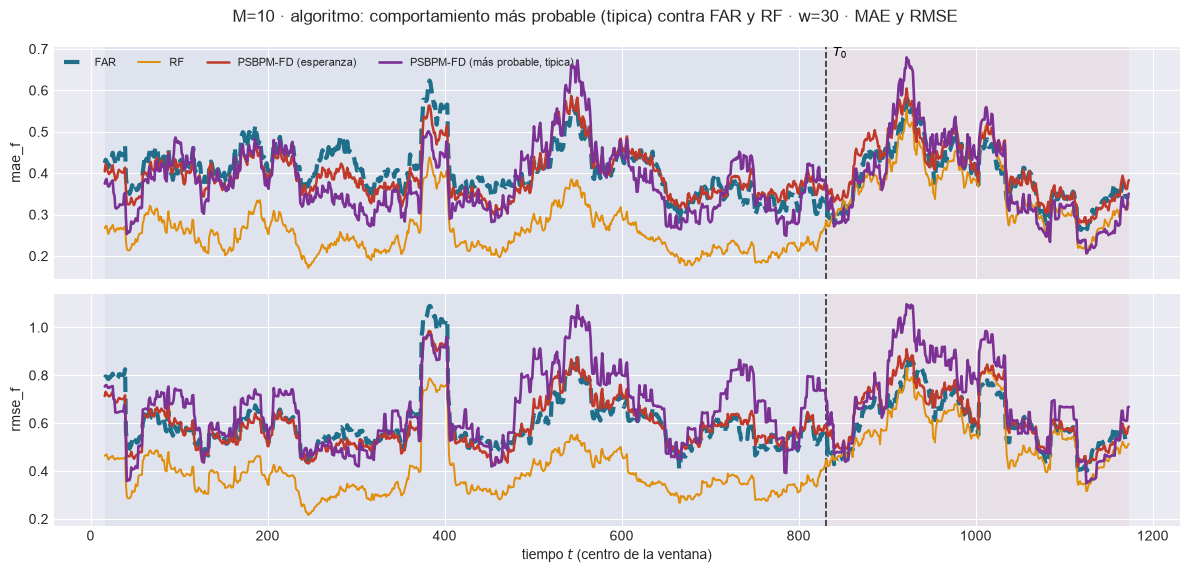

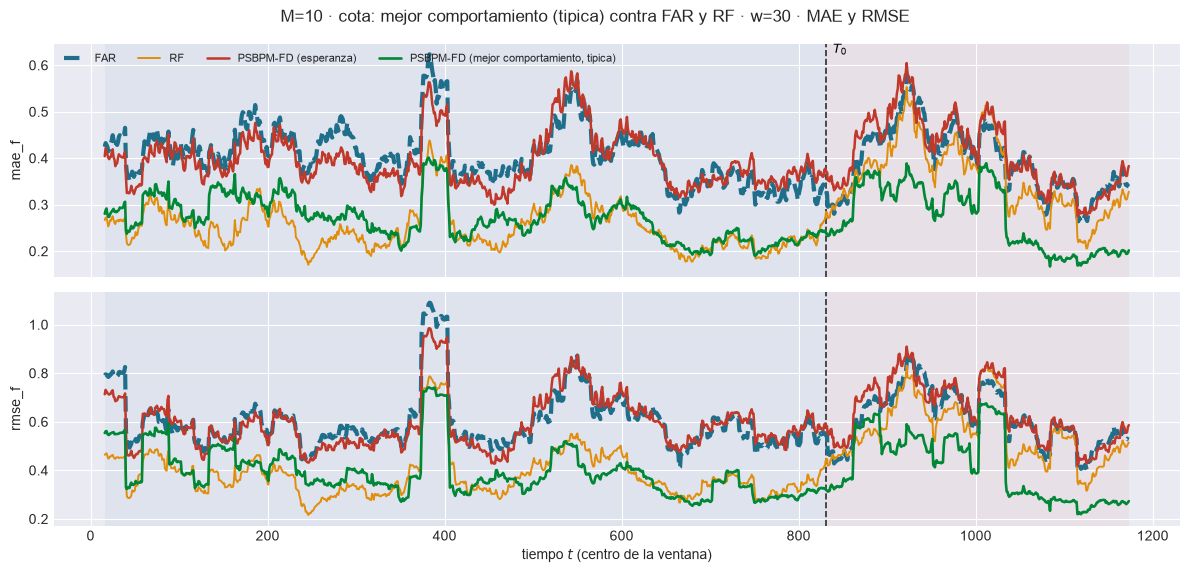

In [10]:
# Ventana móvil del Bloque A con todas las filas (FAR, RF, cuatro predictores, más probable y mejor
# comportamiento por opción): 115_ventana_modelos_w*.csv por M. Luego, dos figuras por M con el ancho
# de referencia: el algoritmo nuevo contra FAR y RF, y la cota contra FAR y RF (la esperanza como referencia).
for M in M_OK:
    tablas_modelos(EST[M], DIS, ORIG, PESOS_TAU, PREFIJO_06)
verificar_cadena_modelos(EST, W_REF)

ESTILOS_06 = dict(ESTILOS_MODELOS_PREDICTORES)
for o, ls in zip(OPCIONES, ("-", "--", "-.")):
    ESTILOS_06[nombre_mp(o)]    = dict(color="#7b3294", lw=1.9, ls=ls, zorder=6)
    ESTILOS_06[nombre_mejor(o)] = dict(color="#008837", lw=1.9, ls=ls, zorder=6)

FIGURAS = (("mas_probable", "algoritmo: comportamiento más probable", nombre_mp(OPCION_FIG)),
           ("mejor", "cota: mejor comportamiento", nombre_mejor(OPCION_FIG)))
for M in M_OK:
    e = EST[M]
    tw = e["tablas_w"][W_REF]
    for sufijo, titulo, fila in FIGURAS:
        tf = tw[tw["modelo"].isin(["FAR", "RF", nombre_psbp("esperanza"), fila])].copy()
        tf.attrs["w"] = W_REF
        plot_ventana_movil(
            tf, T0, METRICAS_A_COLS[:2], columna_grupo="modelo", estilos=ESTILOS_06,
            title=f"M={M} · {titulo} ({OPCION_FIG}) contra FAR y RF · w={W_REF} · MAE y RMSE",
            save_path=str(e["paths"]["out_report"] / f"{PREFIJO_06 + 1}_ventana_{sufijo}_w{W_REF}.png"),
            verbose=False)
        plt.show()


## 6. Resumen en test: ventanas, contra `M`, y por origen con `K ≥ 2`

`116_*`, `117_*`, `118_*_vs_M.png` y `119_resumen_opciones_por_M.csv`.

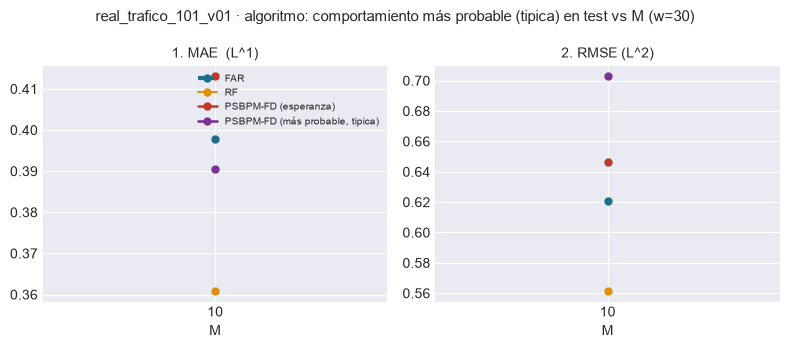

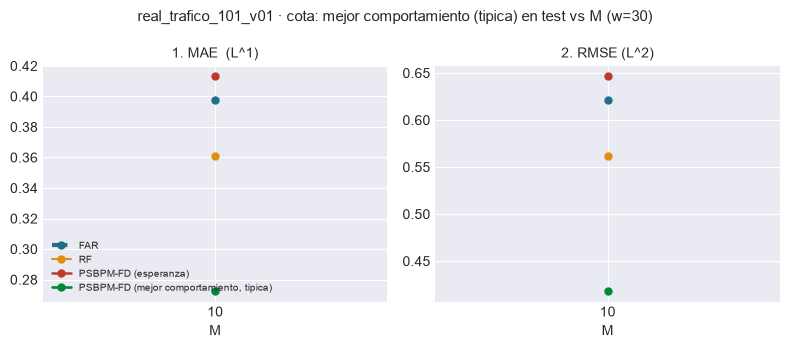

M,10
modelo,
FAR,0.3977
PSBPM-FD (esperanza),0.4130
PSBPM-FD (mediana),0.3762
PSBPM-FD (medoide),0.3838
"PSBPM-FD (mejor comportamiento, mediana)",0.2659
"PSBPM-FD (mejor comportamiento, medoide)",0.2748
"PSBPM-FD (mejor comportamiento, tipica)",0.2727
PSBPM-FD (modal),0.3972
"PSBPM-FD (más probable, mediana)",0.3857


M,10
modelo,
FAR,0.6210
PSBPM-FD (esperanza),0.6463
PSBPM-FD (mediana),0.6577
PSBPM-FD (medoide),0.6614
"PSBPM-FD (mejor comportamiento, mediana)",0.4189
"PSBPM-FD (mejor comportamiento, medoide)",0.4273
"PSBPM-FD (mejor comportamiento, tipica)",0.4184
PSBPM-FD (modal),0.7289
"PSBPM-FD (más probable, mediana)",0.7061


In [11]:
# Resumen sobre las ventanas (test, sin cruzar T0): 116_* y 117_* en el barrido, y las dos figuras contra M.
resumen_06 = resumen_min_max(EST, "ventana_df", "modelo", METRICAS_A, excluir=(PISO,))
resumen_06.to_csv(PATH_BARRIDO / "116_resumen_bloqueA_opciones.csv", index=False)
gana_06, rel_06 = ganadores_por_ventana(EST, "ventana_df", "modelo", METRICAS_A, NIVEL, excluir=(PISO,))
gana_06.to_csv(PATH_BARRIDO / "117_ganador_ventana_opciones.csv", index=False)
rel_06.to_csv(PATH_BARRIDO / "117_razones_opciones.csv", index=False)

prom = promedio_vs_M(resumen_06, "modelo")
for sufijo, titulo, fila in FIGURAS:
    grupos = {k: ESTILOS_06[k] for k in ("FAR", "RF", nombre_psbp("esperanza"), fila)}
    plot_metricas_vs_M(prom, METRICAS_A[:2], grupos,
                       f"{EXPERIMENT_BASE} · {titulo} ({OPCION_FIG}) en test vs M (w={W_REF})",
                       save_path=PATH_BARRIDO / f"{PREFIJO_06 + 5}_{sufijo}_vs_M.png")
    plt.show()

for etiqueta, _c in METRICAS_A[:2]:
    piv = (resumen_06[(resumen_06.metrica == etiqueta) & (resumen_06.bloque == "test")]
           .pivot(index="modelo", columns="M", values="promedio"))
    display(piv.style.format("{:.4f}", na_rep="-").background_gradient(cmap="RdYlGn_r", axis=None)
            .set_caption(f"{etiqueta} · promedio en TEST sobre las ventanas (w={W_REF})"))


In [12]:
# Por origen, en test: todos los orígenes y sólo K >= 2 (donde las opciones difieren de la marginal).
# Cuánto acierta el algoritmo (el mejor es el más probable), cuánto gana cada predicción contra FAR, RF y la
# esperanza, y cuánto gana la cota frente a las mismas referencias.
filas = []
for M in M_OK:
    d = POR_ORIGEN[M]
    d = d[d.bloque == "test"]
    for sub, m in (("todos", np.ones(len(d), bool)), ("K>=2", (d.K >= 2).to_numpy())):
        s = d[m]
        if len(s) == 0:
            filas.append({"M": M, "subconjunto": sub, "origenes": 0}); continue
        fila = {"M": M, "subconjunto": sub, "origenes": len(s),
                "mae_esperanza": s.mae_esperanza.mean(), "mae_FAR": s.mae_FAR.mean(), "mae_RF": s.mae_RF.mean()}
        for o in OPCIONES:
            fila.update({f"mae_mp_{o}": s[f"mae_mp_{o}"].mean(), f"mae_mejor_{o}": s[f"mae_mejor_{o}"].mean(),
                         f"acierto_{o}": s[f"mejor_es_mp_{o}"].mean(),
                         f"mp_gana_FAR_{o}": (s[f"mae_mp_{o}"] < s.mae_FAR).mean(),
                         f"mp_gana_RF_{o}": (s[f"mae_mp_{o}"] < s.mae_RF).mean(),
                         f"mp_gana_esperanza_{o}": (s[f"mae_mp_{o}"] < s.mae_esperanza).mean(),
                         f"mejor_gana_FAR_{o}": (s[f"mae_mejor_{o}"] < s.mae_FAR).mean(),
                         f"mejor_gana_RF_{o}": (s[f"mae_mejor_{o}"] < s.mae_RF).mean()})
        filas.append(fila)
RES_06 = pd.DataFrame(filas)
RES_06.to_csv(PATH_BARRIDO / "119_resumen_opciones_por_M.csv", index=False)
cols = ["origenes", "mae_esperanza", "mae_FAR", "mae_RF"] + \
       [f"{k}_{OPCION_FIG}" for k in ("mae_mp", "mae_mejor", "acierto", "mp_gana_FAR", "mp_gana_RF",
                                      "mp_gana_esperanza", "mejor_gana_FAR", "mejor_gana_RF")]
display(RES_06.set_index(["M", "subconjunto"])[cols].style.format(precision=3)
        .set_caption(f"Test · opción {OPCION_FIG} · MAE medio por origen; acierto = el mejor comportamiento es "
                     "el más probable; *_gana_* = fracción de orígenes"))


## 7. ¿Cuándo elegir por probabilidad acierta? Acierto por tramo de $p_1$

`119_acierto_por_p1.csv` y `119_acierto_por_p1.png`.

M,10
tramo_p1,
"[0.5, 0.6)",0.47
"[0.6, 0.7)",0.66
"[0.7, 0.8)",0.75
"[0.8, 0.9)",0.93
"[0.9, 1.0)",0.98


M,10
tramo_p1,
"[0.5, 0.6)",38
"[0.6, 0.7)",41
"[0.7, 0.8)",59
"[0.8, 0.9)",71
"[0.9, 1.0)",47


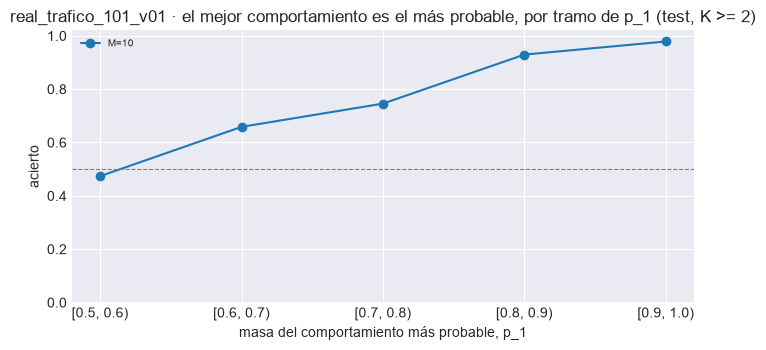

In [13]:
# ¿Cuándo elegir por probabilidad acierta? Entre los orígenes con K >= 2, el acierto (el mejor es el más
# probable) y la ganancia perdida (MAE más probable - MAE mejor) por tramo de la masa p_1 del más probable:
# con 90/10 debería acertar casi siempre; con 60/40 es casi un volado.
filas = []
for M in M_OK:
    d = POR_ORIGEN[M]
    d = d[(d.bloque == "test") & (d.K >= 2)]
    if len(d) == 0:
        continue
    tramo = pd.cut(d.p_1, bins=list(TRAMOS_P1), right=False)
    for tr, s in d.groupby(tramo, observed=True):
        filas.append({"M": M, "tramo_p1": str(tr), "origenes": len(s),
                      **{f"acierto_{o}": s[f"mejor_es_mp_{o}"].mean() for o in OPCIONES},
                      **{f"perdida_mae_{o}": (s[f"mae_mp_{o}"] - s[f"mae_mejor_{o}"]).mean() for o in OPCIONES}})
ACIERTO_P1 = pd.DataFrame(filas)
if len(ACIERTO_P1):
    ACIERTO_P1.to_csv(PATH_BARRIDO / "119_acierto_por_p1.csv", index=False)
    display(ACIERTO_P1.pivot(index="tramo_p1", columns="M", values=f"acierto_{OPCION_FIG}")
            .style.format("{:.2f}", na_rep="-").background_gradient(cmap="RdYlGn", axis=None, vmin=0, vmax=1)
            .set_caption(f"Acierto del algoritmo por tramo de p_1 (test, K >= 2, opción {OPCION_FIG})"))
    display(ACIERTO_P1.pivot(index="tramo_p1", columns="M", values="origenes").style.format("{:.0f}", na_rep="-")
            .set_caption("Orígenes de test con K >= 2 en cada tramo"))
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for M in M_OK:
        s = ACIERTO_P1[ACIERTO_P1.M == M]
        ax.plot(s.tramo_p1, s[f"acierto_{OPCION_FIG}"], marker="o", label=f"M={M}")
    ax.axhline(0.5, color="grey", lw=0.8, ls="--")
    ax.set_ylim(0, 1.02); ax.set_xlabel("masa del comportamiento más probable, p_1"); ax.set_ylabel("acierto")
    ax.set_title(f"{EXPERIMENT_BASE} · el mejor comportamiento es el más probable, por tramo de p_1 (test, K >= 2)")
    ax.legend(fontsize=7, ncol=2)
    fig.tight_layout(); fig.savefig(PATH_BARRIDO / f"{PREFIJO_06 + 6}_acierto_por_p1.png", dpi=130); plt.show()
else:
    print("Sin orígenes de test con K >= 2: el algoritmo coincide con la esperanza en todo el bloque de prueba.")


## 8. Lectura

- **Algoritmo (más probable)**: si su MAE queda por debajo del FAR y del RF donde `K ≥ 2`, el modelo no sólo produce opciones sino que elige bien. Contra la esperanza mide cuánto se pierde por promediar entre comportamientos.
- **Cota (mejor comportamiento)**: cuánto se ganaría acertando el comportamiento, contra las mismas referencias (FAR, RF, esperanza).
- **Acierto por `p_1`**: con masas 90/10 elegir por probabilidad debería acertar casi siempre; con 60/40 no, y ahí es donde la distancia entre el algoritmo y la cota se concentra.
- Con `K = 1` las dos predicciones son el predictor marginal de la misma opción (la esperanza analítica para la típica): en los escenarios unimodales las filas nuevas repiten a la esperanza, y eso es el resultado.
